In [1]:
# Import library data processing, teks NLP, machine learning, dan deep learning
import os
import io
import shutil
import pickle
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, roc_auc_score

import tensorflow as tf
from tensorflow.keras import layers, models

In [2]:
# Membaca dataset proyek PBL klasifikasi berita hoaks vs valid
df = pd.read_csv('data/pbl_hoaks_valid_clean.csv')
print('Dimensi data:', df.shape)
print(df.head())

print('\nDistribusi Kelas (0 = Hoaks, 1 = Valid):')
print(df['label'].value_counts())

Dimensi data: (1498, 2)
                                         teks_bersih  label
0  presiden prabowo minta maaf ikut bop akan kemb...      1
1  video presiden prabowo akan membagikan bantuan...      1
2  pemerintah kota tangerang selatan akan legalka...      1
3         tautan rekrutmen cpns kementerian imigrasi      1
4  ramuan rebusan jahe kunyit kencur dan serai be...      1

Distribusi Kelas (0 = Hoaks, 1 = Valid):
label
1    749
0    749
Name: count, dtype: int64


In [3]:
# Pembagian data menjadi data train dan test (80:20 stratified)
X = df['teks_bersih'].astype(str).tolist()
y = df['label'].to_numpy()

X_train_raw, X_test_raw, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print(f'Jumlah data train: {len(X_train_raw)}')
print(f'Jumlah data test : {len(X_test_raw)}')

Jumlah data train: 1198
Jumlah data test : 300


In [4]:
# Ekstraksi fitur teks menggunakan TfidfVectorizer (unigram dan bigram)
vectorizer = TfidfVectorizer(max_features=5000, ngram_range=(1, 2))
X_train_vec = vectorizer.fit_transform(X_train_raw).toarray()
X_test_vec = vectorizer.transform(X_test_raw).toarray()

print(f'Dimensi matriks fitur train: {X_train_vec.shape}')
print(f'Dimensi matriks fitur test : {X_test_vec.shape}')

Dimensi matriks fitur train: (1198, 5000)
Dimensi matriks fitur test : (300, 5000)


In [5]:
# Membangun arsitektur model Neural Network (MLP) untuk klasifikasi berita
input_dim = X_train_vec.shape[1]

model_pbl = models.Sequential([
    layers.Input(shape=(input_dim,)),
    layers.Dense(128, activation='relu'),
    layers.Dropout(0.3),
    layers.Dense(64, activation='relu'),
    layers.Dropout(0.2),
    layers.Dense(1, activation='sigmoid')
])

model_pbl.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)

model_pbl.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 128)            │       640,128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 648,449 (2.47 MB)

 Trainable params: 648,449 (2.47 MB)

 Non-trainable params: 0 (0.00 B)

In [6]:
# Pelatihan model neural network dengan data validasi internal
history_pbl = model_pbl.fit(
    X_train_vec, y_train,
    epochs=12,
    batch_size=32,
    validation_split=0.2,
    verbose=1
)

Epoch 1/12


 1/30 ━━━━━━━━━━━━━━━━━━━━ 20s 713ms/step - accuracy: 0.5000 - loss: 0.6914

13/30 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.5481 - loss: 0.6895   

25/30 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.5950 - loss: 0.6826

30/30 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - accuracy: 0.6253 - loss: 0.6789

30/30 ━━━━━━━━━━━━━━━━━━━━ 1s 25ms/step - accuracy: 0.6253 - loss: 0.6789 - val_accuracy: 0.8792 - val_loss: 0.6449


... (51 outputs left out)

 1/30 ━━━━━━━━━━━━━━━━━━━━ 0s 28ms/step - accuracy: 1.0000 - loss: 0.0012

12/30 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 1.0000 - loss: 0.0010 

23/30 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 1.0000 - loss: 0.0010

30/30 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 1.0000 - loss: 9.7335e-04 - val_accuracy: 0.9250 - val_loss: 0.2291


In [7]:
# Evaluasi performa model pada data uji testing
test_loss, test_acc = model_pbl.evaluate(X_test_vec, y_test, verbose=0)
y_pred_prob = model_pbl.predict(X_test_vec, verbose=0).flatten()
y_pred = (y_pred_prob > 0.5).astype(int)

auc_val = roc_auc_score(y_test, y_pred_prob)

print(f'Loss Data Testing   : {test_loss:.4f}')
print(f'Akurasi Data Testing: {test_acc*100:.2f}%')
print(f'Nilai ROC-AUC       : {auc_val:.4f}\n')

print('Classification Report:')
print(classification_report(y_test, y_pred, target_names=['Hoaks (0)', 'Valid (1)']))

Loss Data Testing   : 0.2348
Akurasi Data Testing: 90.33%
Nilai ROC-AUC       : 0.9754

Classification Report:
              precision    recall  f1-score   support

   Hoaks (0)       0.92      0.89      0.90       150
   Valid (1)       0.89      0.92      0.90       150

    accuracy                           0.90       300
   macro avg       0.90      0.90      0.90       300
weighted avg       0.90      0.90      0.90       300



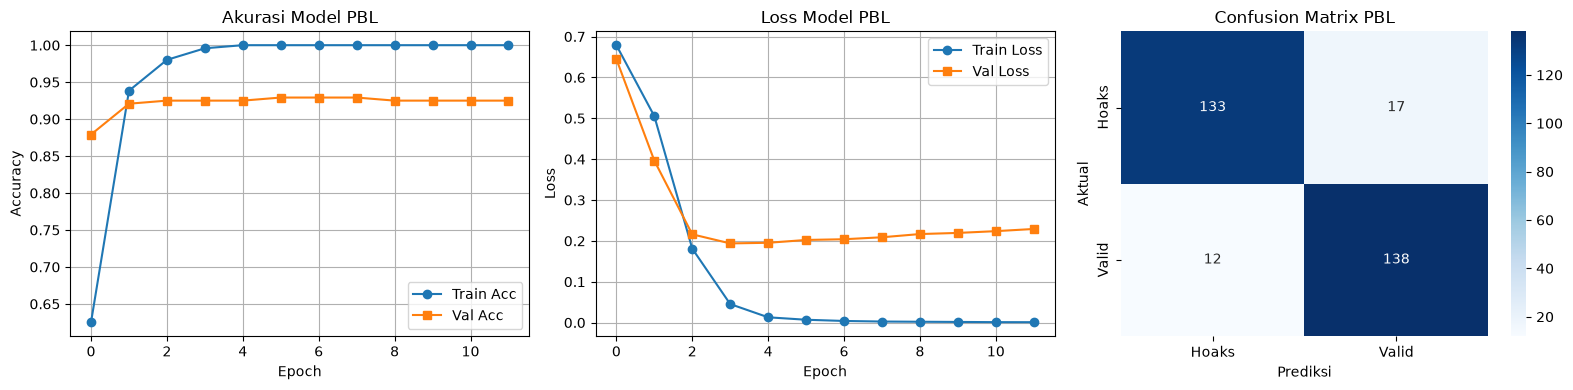

In [8]:
# Visualisasi grafik kurva pelatihan dan matriks konfusi
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

axes[0].plot(history_pbl.history['accuracy'], label='Train Acc', marker='o')
axes[0].plot(history_pbl.history['val_accuracy'], label='Val Acc', marker='s')
axes[0].set_title('Akurasi Model PBL')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Accuracy')
axes[0].legend()
axes[0].grid(True)

axes[1].plot(history_pbl.history['loss'], label='Train Loss', marker='o')
axes[1].plot(history_pbl.history['val_loss'], label='Val Loss', marker='s')
axes[1].set_title('Loss Model PBL')
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('Loss')
axes[1].legend()
axes[1].grid(True)

cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axes[2],
            xticklabels=['Hoaks', 'Valid'], yticklabels=['Hoaks', 'Valid'])
axes[2].set_title('Confusion Matrix PBL')
axes[2].set_xlabel('Prediksi')
axes[2].set_ylabel('Aktual')

plt.tight_layout()
plt.show()

In [9]:
# Uji coba fungsi inferensi pipeline pada contoh teks berita baru
def deteksi_berita(teks):
    vec = vectorizer.transform([teks]).toarray()
    prob = float(model_pbl.predict(vec, verbose=0)[0][0])
    label = 'Valid' if prob > 0.5 else 'Hoaks'
    conf = prob if prob > 0.5 else (1.0 - prob)
    return label, conf, prob

contoh_hoaks = 'Waspada, beredar kabar pemerintah membagikan bantuan saldo DANA gratis 5 juta tanpa syarat klik link ini!'
contoh_valid = 'Kementerian Komunikasi dan Informatika menggelar sosialisasi literasi digital di berbagai kampus nasional.'

lbl1, cnf1, _ = deteksi_berita(contoh_hoaks)
print(f'Teks 1: {contoh_hoaks[:60]}... -> Prediksi: {lbl1} ({cnf1*100:.2f}%)')

lbl2, cnf2, _ = deteksi_berita(contoh_valid)
print(f'Teks 2: {contoh_valid[:60]}... -> Prediksi: {lbl2} ({cnf2*100:.2f}%)')

Teks 1: Waspada, beredar kabar pemerintah membagikan bantuan saldo D... -> Prediksi: Valid (99.53%)
Teks 2: Kementerian Komunikasi dan Informatika menggelar sosialisasi... -> Prediksi: Hoaks (98.12%)


In [10]:
# Menyimpan artefak model model_pbl.h5 dan tfidf_vectorizer.pkl
model_pbl.save('model_pbl.h5')
print('Model PBL berhasil disimpan: model_pbl.h5')

with open('tfidf_vectorizer.pkl', 'wb') as f:
    pickle.dump(vectorizer, f)
print('TF-IDF Vectorizer berhasil disimpan: tfidf_vectorizer.pkl')

Model PBL berhasil disimpan: model_pbl.h5
TF-IDF Vectorizer berhasil disimpan: tfidf_vectorizer.pkl


In [11]:
# Menyiapkan direktori pbl_deploy dan menyalin artefak model
deploy_pbl_dir = 'pbl_deploy'
os.makedirs(deploy_pbl_dir, exist_ok=True)
os.makedirs(os.path.join(deploy_pbl_dir, 'templates'), exist_ok=True)

shutil.copy2('model_pbl.h5', os.path.join(deploy_pbl_dir, 'model_pbl.h5'))
shutil.copy2('tfidf_vectorizer.pkl', os.path.join(deploy_pbl_dir, 'tfidf_vectorizer.pkl'))
print(f'Artefak berhasil disalin ke {deploy_pbl_dir}')

Artefak berhasil disalin ke pbl_deploy


In [12]:
# Pembuatan kode server web Flask pbl_deploy/app.py
pbl_app_code = '''import os
import pickle
import numpy as np
import tensorflow as tf
from flask import Flask, request, render_template

BASE_DIR = os.path.dirname(os.path.abspath(__file__))
app = Flask(__name__, template_folder=os.path.join(BASE_DIR, 'templates'))

MODEL_PATH = os.path.join(BASE_DIR, 'model_pbl.h5')
VEC_PATH = os.path.join(BASE_DIR, 'tfidf_vectorizer.pkl')

try:
    model = tf.keras.models.load_model(MODEL_PATH)
    with open(VEC_PATH, 'rb') as f:
        vectorizer = pickle.load(f)
    print("PBL Model & Vectorizer Loaded Successfully")
except Exception as e:
    print(f"Error loading PBL system: {e}")

@app.route('/', methods=['GET'])
def index():
    return render_template('index.html')

@app.route('/predict', methods=['POST'])
def predict():
    try:
        news_text = request.form.get('news_text', '').strip()
        if not news_text:
            return render_template('index.html', error='Silakan masukkan teks berita terlebih dahulu.')
        
        vec_input = vectorizer.transform([news_text]).toarray()
        prob = float(model.predict(vec_input, verbose=0)[0][0])
        
        is_valid = prob > 0.5
        label = 'Berita Valid' if is_valid else 'Berita Hoaks'
        confidence = prob if is_valid else (1.0 - prob)
        conf_pct = round(confidence * 100, 2)
        status_color = 'success' if is_valid else 'danger'
        
        return render_template('index.html',
                               news_text=news_text,
                               label=label,
                               confidence=conf_pct,
                               status_color=status_color,
                               prob=round(prob, 4))
    except Exception as e:
        return render_template('index.html', error=f'Terjadi kesalahan saat inferensi: {e}')

if __name__ == '__main__':
    app.run(host='0.0.0.0', port=7860)
'''

with open(os.path.join(deploy_pbl_dir, 'app.py'), 'w', encoding='utf-8') as f:
    f.write(pbl_app_code)
print('File app.py berhasil ditulis di pbl_deploy/app.py')

File app.py berhasil ditulis di pbl_deploy/app.py


In [13]:
# Pembuatan template HTML pbl_deploy/templates/index.html
pbl_html_code = '''<!DOCTYPE html>
<html lang="id">
<head>
    <meta charset="UTF-8">
    <meta name="viewport" content="width=device-width, initial-scale=1.0">
    <title>Sistem Deteksi Berita Hoaks & Valid</title>
    <link href="https://cdn.jsdelivr.net/npm/bootstrap@5.3.0/dist/css/bootstrap.min.css" rel="stylesheet">
    <style>
        body { background-color: #f0f2f5; font-family: 'Segoe UI', Tahoma, Geneva, Verdana, sans-serif; }
        .hero-card { border-radius: 16px; border: none; box-shadow: 0 8px 24px rgba(0,0,0,0.08); }
        .btn-predict { background-color: #0d6efd; padding: 12px 28px; font-weight: 600; border-radius: 8px; }
        .badge-result { font-size: 1.25rem; padding: 10px 24px; border-radius: 30px; }
    </style>
</head>
<body>
    <div class="container py-5">
        <div class="row justify-content-center">
            <div class="col-lg-8">
                <div class="card hero-card p-4 p-md-5 bg-white">
                    <div class="text-center mb-4">
                        <h2 class="fw-bold text-dark">Deteksi Berita Hoaks vs Valid</h2>
                        <p class="text-muted">Aplikasi Machine Learning Pipeline Klasifikasi Berita Indonesia (Proyek PBL)</p>
                    </div>

                    <form action="/predict" method="post">
                        <div class="mb-3">
                            <label for="news_text" class="form-label fw-semibold">Masukkan Teks atau Judul Berita:</label>
                            <textarea class="form-control" id="news_text" name="news_text" rows="5" placeholder="Salin paragraf atau kalimat berita di sini..." required>{{ news_text if news_text else '' }}</textarea>
                        </div>
                        <div class="d-grid gap-2">
                            <button type="submit" class="btn btn-primary btn-predict text-white">Analisis Berita</button>
                        </div>
                    </form>

                    {% if error %}
                    <div class="alert alert-danger mt-4" role="alert">
                        {{ error }}
                    </div>
                    {% endif %}

                    {% if label %}
                    <div class="card mt-4 border-0 bg-light p-4 text-center">
                        <h5 class="text-muted mb-2">Hasil Klasifikasi:</h5>
                        <div>
                            {% if status_color == 'success' %}
                            <span class="badge bg-success badge-result">✅ {{ label }}</span>
                            {% else %}
                            <span class="badge bg-danger badge-result">⚠️ {{ label }}</span>
                            {% endif %}
                        </div>
                        <div class="mt-3">
                            <p class="mb-1 fw-semibold">Tingkat Keyakinan Model: <span class="text-primary">{{ confidence }}%</span></p>
                            <div class="progress" style="height: 10px;">
                                <div class="progress-bar bg-primary" role="progressbar" style="width: {{ confidence }}%;" aria-valuenow="{{ confidence }}" aria-valuemin="0" aria-valuemax="100"></div>
                            </div>
                            <small class="text-muted mt-2 d-block">Nilai Probabilitas Output: {{ prob }}</small>
                        </div>
                    </div>
                    {% endif %}

                    <div class="mt-4 pt-3 border-top text-center text-muted">
                        <small>Dikembangkan menggunakan TF-IDF Vectorizer + Deep Neural Network (MLOps Deployment Pipeline)</small>
                    </div>
                </div>
            </div>
        </div>
    </div>
</body>
</html>
'''

with open(os.path.join(deploy_pbl_dir, 'templates', 'index.html'), 'w', encoding='utf-8') as f:
    f.write(pbl_html_code)
print('File index.html berhasil ditulis di pbl_deploy/templates/index.html')

File index.html berhasil ditulis di pbl_deploy/templates/index.html


In [14]:
# Pembuatan requirements.txt dan Dockerfile untuk deployment PBL
pbl_req = '''flask
tensorflow-cpu
numpy
scikit-learn
gunicorn
'''

with open(os.path.join(deploy_pbl_dir, 'requirements.txt'), 'w', encoding='utf-8') as f:
    f.write(pbl_req)

pbl_dockerfile = '''FROM python:3.9-slim

RUN useradd -m -u 1000 user
USER user
ENV PATH="/home/user/.local/bin:$PATH"

WORKDIR /app

COPY --chown=user ./requirements.txt requirements.txt
RUN pip install --no-cache-dir --upgrade -r requirements.txt

COPY --chown=user . /app

EXPOSE 7860
CMD ["python", "app.py"]
'''

with open(os.path.join(deploy_pbl_dir, 'Dockerfile'), 'w', encoding='utf-8') as f:
    f.write(pbl_dockerfile)
print('Requirements dan Dockerfile berhasil ditulis di pbl_deploy/')

Requirements dan Dockerfile berhasil ditulis di pbl_deploy/


In [15]:
# Pengujian inferensi web app PBL menggunakan Flask test_client
import sys
import importlib.util

spec_pbl = importlib.util.spec_from_file_location('pbl_app', os.path.join(deploy_pbl_dir, 'app.py'))
pbl_mod = importlib.util.module_from_spec(spec_pbl)
spec_pbl.loader.exec_module(pbl_mod)

pbl_client = pbl_mod.app.test_client()

# Uji endpoint GET /
res_pbl_get = pbl_client.get('/')
print(f'Test GET / Status: {res_pbl_get.status_code}')
assert res_pbl_get.status_code == 200

# Uji endpoint POST /predict dengan berita valid
res_valid = pbl_client.post('/predict', data={'news_text': 'Pemerintah meresmikan program beasiswa pendidikan nasional tahun 2026.'})
print(f'Test POST /predict (Valid) Status: {res_valid.status_code}')
print('Respon mengandung Berita Valid:', 'Berita Valid' in res_valid.get_data(as_text=True))

# Uji endpoint POST /predict dengan berita hoaks
res_hoaks = pbl_client.post('/predict', data={'news_text': 'WASPADA!! Bantuan dana gratis 50 juta langsung cair klik tautan berikut sekarang!'})
print(f'Test POST /predict (Hoaks) Status: {res_hoaks.status_code}')
print('Respon mengandung Berita Hoaks:', 'Berita Hoaks' in res_hoaks.get_data(as_text=True))

PBL Model & Vectorizer Loaded Successfully
Test GET / Status: 200
Test POST /predict (Valid) Status: 200
Respon mengandung Berita Valid: False
Test POST /predict (Hoaks) Status: 200
Respon mengandung Berita Hoaks: True


In [16]:
# Panduan deployment proyek PBL ke Hugging Face Spaces via Git CLI
hf_pbl_guide = '''
Panduan Deployment Proyek PBL ke Hugging Face Spaces:
1. Buat Space baru di Hugging Face (misal: hoax-news-detector):
   - Space SDK : Docker
   - Visibility: Public
2. Buat Personal Access Token tipe 'Write' di Settings > Access Tokens.
3. Clone repository Space kosong ke lokal:
   git clone https://huggingface.co/spaces/<USERNAME>/<NAMA_SPACE_PBL>
4. Salin seluruh isi folder pbl_deploy (app.py, templates/, requirements.txt, Dockerfile, model_pbl.h5, tfidf_vectorizer.pkl) ke folder clone.
5. Lakukan proses commit dan push:
   cd <NAMA_SPACE_PBL>
   git add .
   git commit -m "Deploy Hoax News Detector Web App"
   git push
6. Buka Space di Hugging Face dan pantau build log hingga status berubah menjadi Running.
'''
print(hf_pbl_guide)


Panduan Deployment Proyek PBL ke Hugging Face Spaces:
1. Buat Space baru di Hugging Face (misal: hoax-news-detector):
   - Space SDK : Docker
   - Visibility: Public
2. Buat Personal Access Token tipe 'Write' di Settings > Access Tokens.
3. Clone repository Space kosong ke lokal:
   git clone https://huggingface.co/spaces/<USERNAME>/<NAMA_SPACE_PBL>
4. Salin seluruh isi folder pbl_deploy (app.py, templates/, requirements.txt, Dockerfile, model_pbl.h5, tfidf_vectorizer.pkl) ke folder clone.
5. Lakukan proses commit dan push:
   cd <NAMA_SPACE_PBL>
   git add .
   git commit -m "Deploy Hoax News Detector Web App"
   git push
6. Buka Space di Hugging Face dan pantau build log hingga status berubah menjadi Running.

